# α-BaCu₂Se₂ Bayesian optimization from XRD metrics

Explores how XRD metrics (phase purity, crystallinity) relate to synthesis parameters, then runs Gaussian-process Bayesian optimization to suggest next synthesis conditions. The objective and GP functions live in `xrd_bo_optimization_tf.bayesian_opt`; exploratory plots use the colorblind-safe styling from `xrd_bo_optimization_tf.plotting`. Outputs go to `data/results/` and `outputs/figures/`.

In [19]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd

from xrd_bo_optimization_tf.bayesian_opt import prepare_optimization_data
from xrd_bo_optimization_tf.config import (
    BO_PARAMETER_COLUMNS,
    GENERATED_XRD_METRICS_CSV,
    NOMAD_SYNTHESIS_CSV,
    XRD_METRICS_CSV,
)

metrics_path = (
    GENERATED_XRD_METRICS_CSV
    if GENERATED_XRD_METRICS_CSV.is_file()
    else XRD_METRICS_CSV
)
metrics = pd.read_csv(metrics_path)
synthesis = pd.read_csv(NOMAD_SYNTHESIS_CSV)

# Include pulse knobs and the process descriptors (CBC ratio, spin-to-Se day gap).
df_bo = prepare_optimization_data(
    metrics, synthesis=synthesis, include_pulse=True, include_process=True
)
BO_PARAMS = df_bo.attrs["parameter_columns"]

print(f"Loaded {len(metrics)} metric rows from {metrics_path}")
print(f"Using {len(df_bo)} complete observations for optimization")
print(f"Optimization parameters ({len(BO_PARAMS)}): {list(BO_PARAMS)}")
print("\nNote: se_pulse_count is collinear with selenization_time_s and is excluded;")
print("mo_coated and n_spin_cycles are kept as reported descriptors (too sparse for BO).")

Loaded 25 metric rows from /home/nomad-lanasc/xrd-bo-optimization-tf/data/results/bacuse2_xrd_analysis_metrics.csv
Using 21 complete observations for optimization
Optimization parameters (9): ['spin_speed_rpm', 'soft_bake_temp_c', 'hard_bake_temp_c', 'selenization_temp_c', 'selenization_time_s', 'se_pulse_on_ms', 'se_pulse_off_ms', 'cbc_ratio', 'spin_to_se_days']

Note: se_pulse_count is collinear with selenization_time_s and is excluded;
mo_coated and n_spin_cycles are kept as reported descriptors (too sparse for BO).


In [13]:
columns = ['sample_id', *BO_PARAMS, 'crystallinity', 'phase_purity', 'crystallinity_norm', 'objective']
print(df_bo[columns].sort_values('objective', ascending=False).round(3).to_string(index=False))
best = df_bo.loc[df_bo['objective'].idxmax()]
print(f'\nBest observed objective: {best["objective"]:.3f} ({best["sample_id"]})')

sample_id  spin_speed_rpm  soft_bake_temp_c  hard_bake_temp_c  selenization_temp_c  selenization_time_s  se_pulse_on_ms  se_pulse_off_ms  cbc_ratio  spin_to_se_days  crystallinity  phase_purity  crystallinity_norm  objective
 260429B2          2000.0             100.0             250.0                540.0               1800.0           500.0           2700.0      0.629             0.94          2.915         1.000               1.000      1.000
 260929A3          1500.0             225.0             225.0                540.0               1200.0          1000.0           2200.0      0.628             0.81          2.830         1.000               0.951      0.985
 260721D6          1500.0             100.0             250.0                560.0               1200.0          1000.0           2200.0      0.629             1.01          2.886         0.915               0.983      0.936
 260721D2          1500.0             100.0             250.0                520.0               120

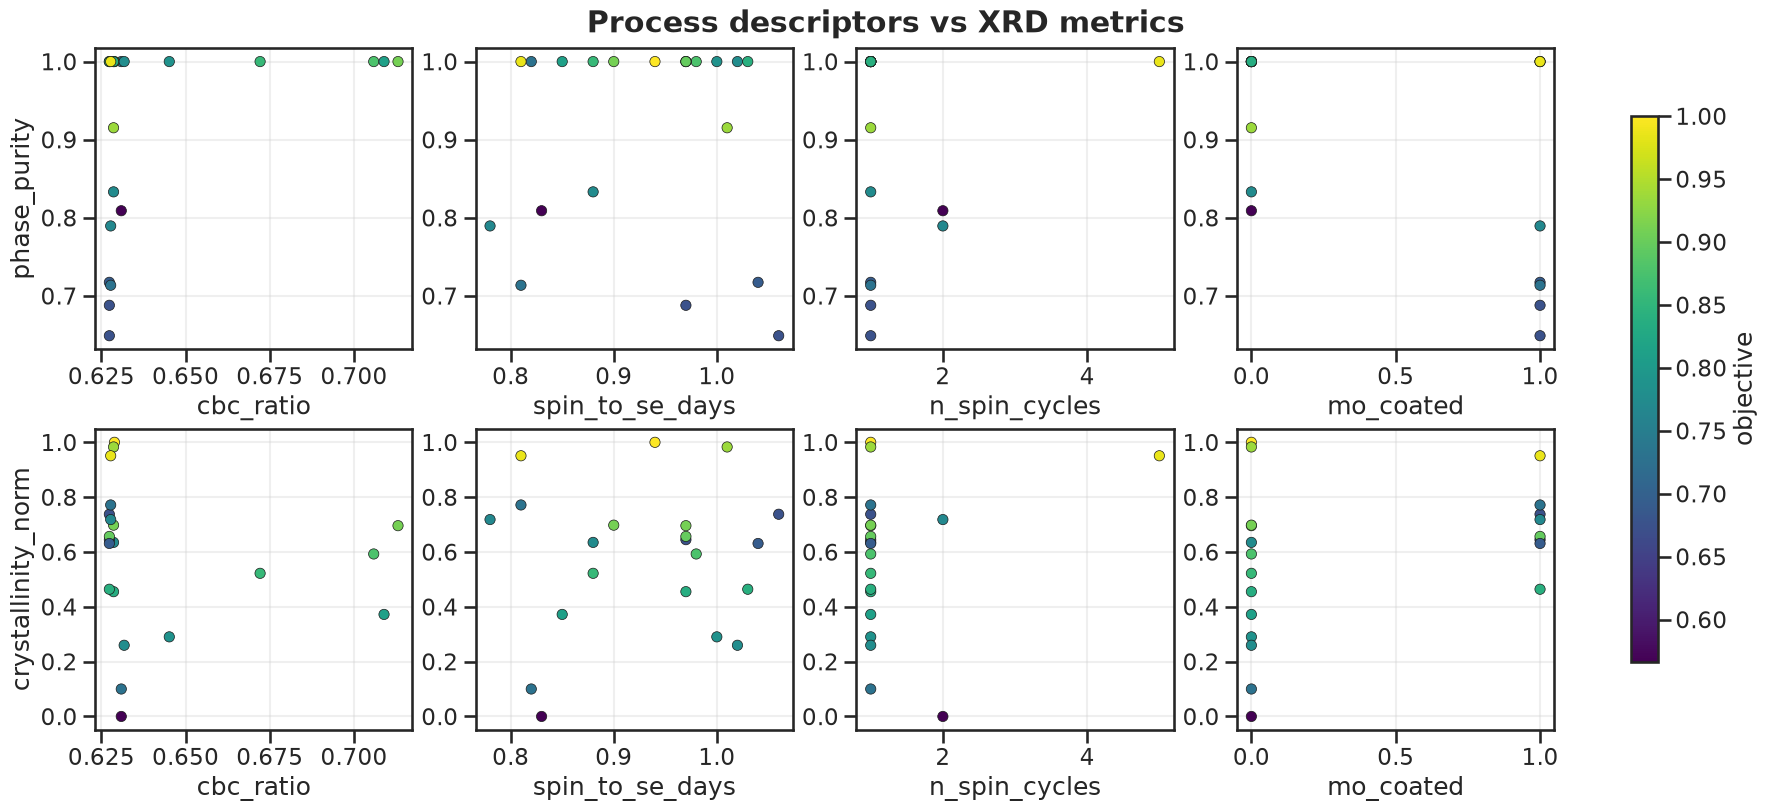

In [20]:
# Exploratory view of the new process descriptors vs the metrics.
import matplotlib.pyplot as plt

import xrd_bo_optimization_tf.plotting as plotting

new_vars = ["cbc_ratio", "spin_to_se_days", "n_spin_cycles", "mo_coated"]
figure, axes = plt.subplots(
    2, len(new_vars), figsize=(4.4 * len(new_vars), 8), layout="constrained"
)
for col_index, var in enumerate(new_vars):
    for row_index, metric in enumerate(("phase_purity", "crystallinity_norm")):
        axis = axes[row_index, col_index]
        scatter = axis.scatter(
            df_bo[var], df_bo[metric], c=df_bo["objective"],
            cmap="viridis", s=55, edgecolor="k", linewidth=0.5,
        )
        axis.set_xlabel(var)
        if col_index == 0:
            axis.set_ylabel(metric)
        axis.grid(alpha=0.3)
figure.colorbar(scatter, ax=axes, label="objective", shrink=0.8)
figure.suptitle("Process descriptors vs XRD metrics", fontweight="bold")
figure.savefig(
    plotting.FIGURES_DIR / "bacuse2_bo_process_descriptors.png",
    dpi=150, bbox_inches="tight",
)
plt.show()

## Exploratory: XRD metrics vs synthesis parameters

Which synthesis knobs move phase purity and crystallinity? Spearman rank correlation (robust for small n) plus a metric-vs-parameter grid and a GP-predicted objective surface over the two strongest parameters.

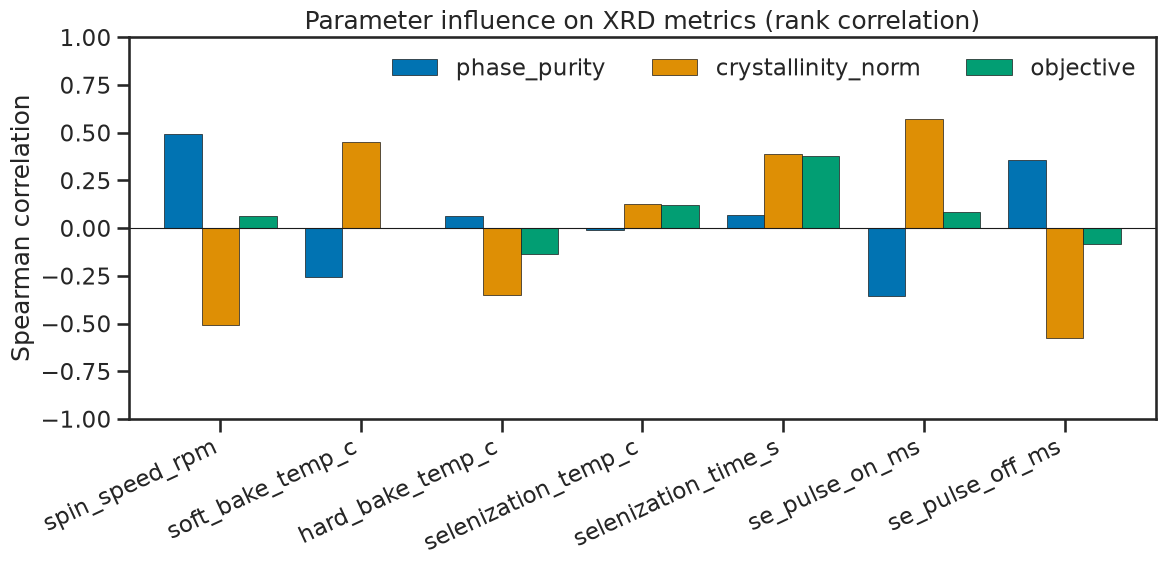

In [3]:
import importlib

import matplotlib.pyplot as plt

import xrd_bo_optimization_tf.plotting as plotting

importlib.reload(plotting)

from xrd_bo_optimization_tf.config import FIGURES_DIR

correlation_figure = plotting.plot_correlation_bars(
    df_bo,
    BO_PARAMS,
    output_path=FIGURES_DIR / 'bacuse2_bo_correlations.png',
)
plt.show()

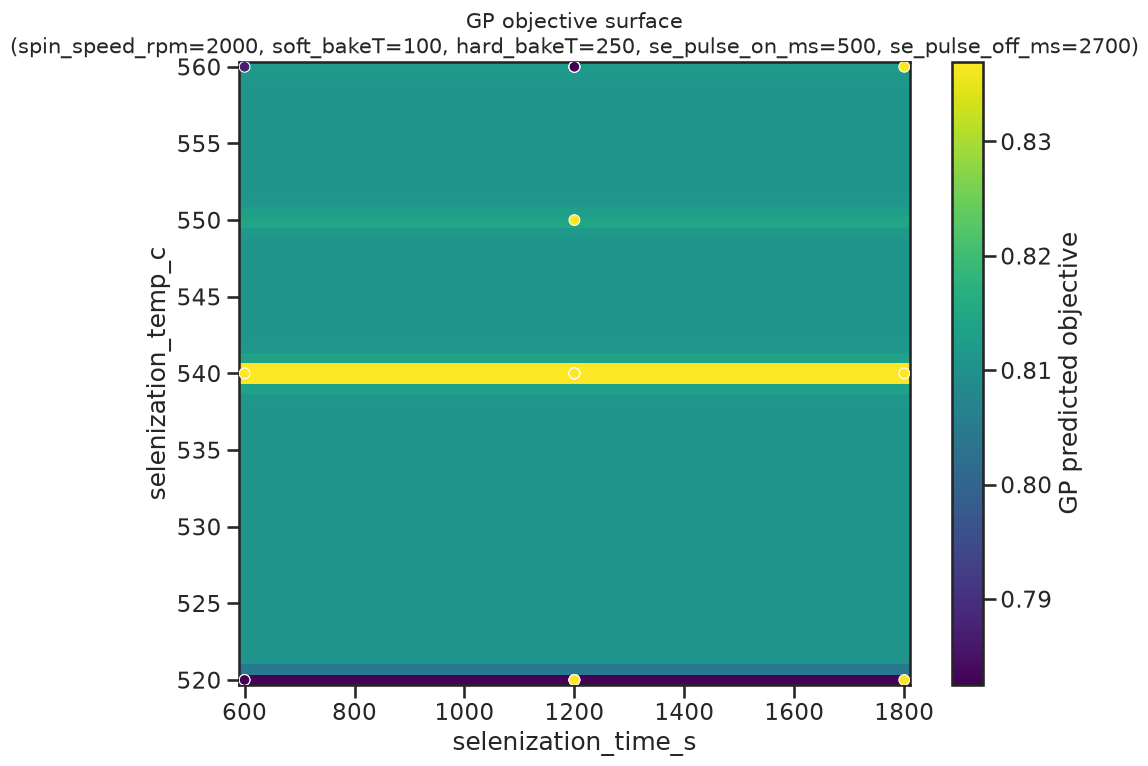

In [4]:
# GP-predicted objective surface over the two most influential core parameters.
surface_figure = plotting.plot_gp_surface(
    df_bo,
    param_x='selenization_time_s',
    param_y='selenization_temp_c',
    output_path=FIGURES_DIR / 'bacuse2_bo_gp_surface.png',
)
plt.show()

## Bayesian optimization

Fit a Gaussian process over the observed films and suggest the next synthesis conditions that maximize expected improvement of the objective ($0.7 \times$ phase purity $+\, 0.3 \times$ normalized crystallinity).

 rank  spin_speed_rpm  soft_bake_temp_c  hard_bake_temp_c  selenization_temp_c  selenization_time_s  se_pulse_on_ms  se_pulse_off_ms  cbc_ratio  spin_to_se_days  predicted_objective  predicted_std
    1          1978.2             166.5             246.5                538.0               1072.9           846.1           2680.0        0.7              0.9                0.811          0.107
    2          1832.1             169.7             246.2                538.2                994.1           925.7           2673.8        0.6              0.9                0.811          0.107
    3          1852.8             179.6             246.1                547.1                876.6           672.7           2684.3        0.7              0.9                0.811          0.107
    4          2000.0             116.4             250.0                543.4                918.9           665.7           2644.9        0.7              0.9                0.811          0.107
    5          

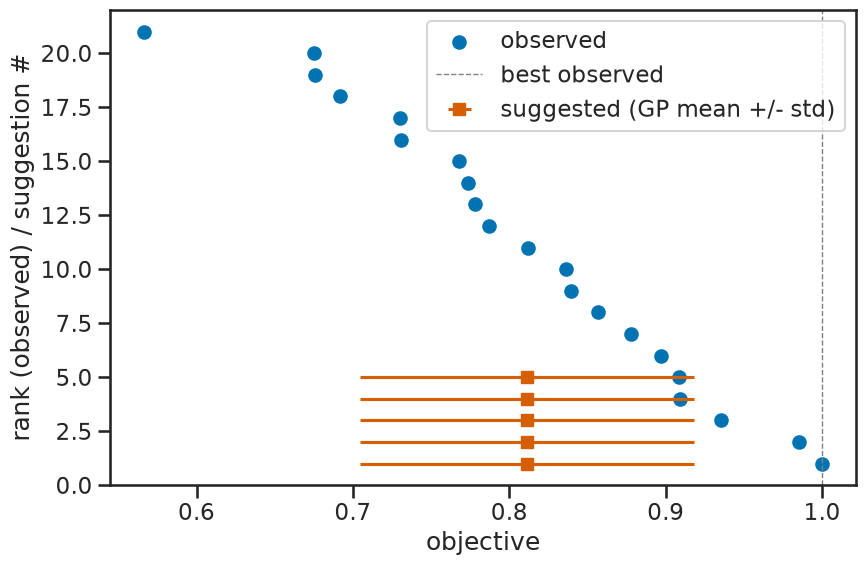

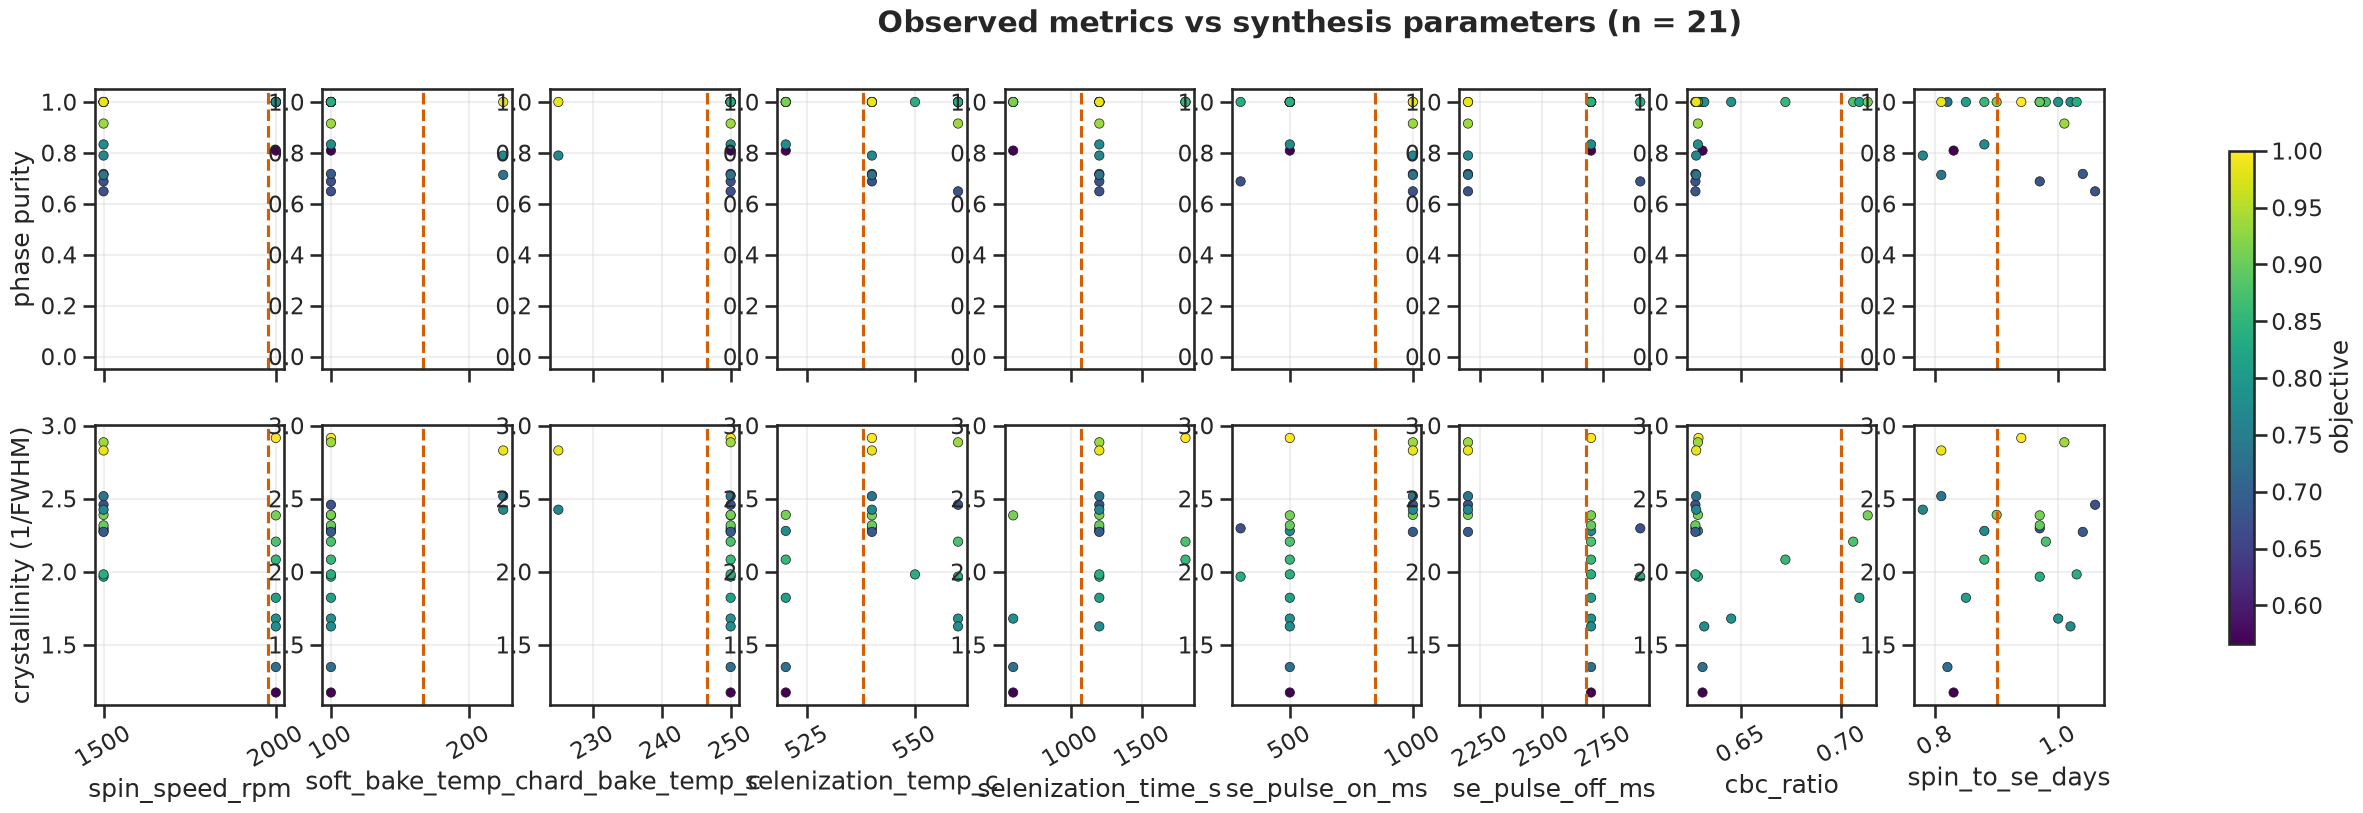

In [15]:
import matplotlib.pyplot as plt

import xrd_bo_optimization_tf.plotting as plotting
from xrd_bo_optimization_tf.bayesian_opt import save_suggestions, suggest_next_conditions
from xrd_bo_optimization_tf.config import FIGURES_DIR

suggestions = suggest_next_conditions(df_bo, n_suggestions=5, random_state=0)
suggestions_path = save_suggestions(suggestions)
print(suggestions.round(3).to_string(index=False))
print(f'\nSaved suggestions to {suggestions_path}')

objective_figure = plotting.plot_bo_suggestions(
    df_bo, suggestions, FIGURES_DIR / 'bacuse2_bo_suggestions.png'
)
parameter_figure = plotting.plot_parameter_metrics(
    df_bo, suggestions, parameter_columns=BO_PARAMS,
    output_path=FIGURES_DIR / 'bacuse2_bo_parameter_plots.png',
)
plt.show()